<a href="https://colab.research.google.com/github/anishsikdar1102-glitch/anish-sikdar-projects/blob/main/Exp%208%3A%20Implement%20a%20classification%20model%20to%20distinguish%20between%20normal%20and%20abnormal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

def load_ecg_csv(path):
    # Kaggle MIT-BIH CSV files have no header:
    # 187 signal points followed by the class label.
    data = pd.read_csv(path, header=None)
    data = data.apply(pd.to_numeric, errors="coerce").dropna()

    if data.shape[1] != 188:
        raise ValueError(
            f"{path} should have 188 columns: 187 signal values + 1 label. "
            f"Found {data.shape[1]}."
        )

    signals = data.iloc[:, :-1].to_numpy(dtype=float)
    labels = data.iloc[:, -1].astype(int).to_numpy()

    # Class 0 is normal; all other heartbeat classes are abnormal.
    binary_labels = np.where(labels == 0, 0, 1)
    return signals, binary_labels

def extract_features(signal_matrix):
    """Extract statistical, amplitude, slope, and frequency features."""
    rows = []

    for signal in signal_matrix:
        signal = np.asarray(signal, dtype=float)
        differences = np.diff(signal)
        centered = signal - np.mean(signal)
        spectrum = np.abs(np.fft.rfft(centered))
        power = spectrum ** 2

        # Divide the waveform into four regions and summarize each.
        regions = np.array_split(signal, 4)
        region_means = [np.mean(part) for part in regions]
        region_stds = [np.std(part) for part in regions]

        row = [
            np.mean(signal),
            np.std(signal),
            np.min(signal),
            np.max(signal),
            np.ptp(signal),
            np.median(signal),
            np.percentile(signal, 25),
            np.percentile(signal, 75),
            np.sqrt(np.mean(signal ** 2)),       # RMS amplitude
            np.mean(signal ** 2),                # signal energy per sample
            np.mean(np.abs(differences)),        # average slope magnitude
            np.std(differences),
            np.max(np.abs(differences)),
            np.sum(np.diff(np.sign(signal)) != 0),  # zero crossings
            np.argmax(signal),
            np.sum(power),                       # frequency-domain energy
            np.argmax(spectrum),                 # strongest frequency bin
            *region_means,
            *region_stds,
        ]
        rows.append(row)

    return np.asarray(rows)

In [11]:
# 1. Load the MIT-BIH train and test CSV datasets
train_path = Path("/content/mitbih_train.csv")
test_path = Path("/content/mitbih_test.csv")

train_signals, y_train = load_ecg_csv(train_path)
test_signals, y_test = load_ecg_csv(test_path)

print("Data loaded successfully!")
print("Training samples:", len(y_train))
print("Test samples:", len(y_test))
print("Training classes distribution (0=normal, 1=abnormal):", np.bincount(y_train))

Data loaded successfully!
Training samples: 87554
Test samples: 21892
Training classes distribution (0=normal, 1=abnormal): [72471 15083]


In [12]:
# 2. Extract engineered statistical and spectral features from ECG signals
print("Extracting training features...")
X_train = extract_features(train_signals)

print("Extracting testing features...")
X_test = extract_features(test_signals)

print("Feature extraction complete!")
print("Features matrix shape:", X_train.shape)

Extracting training features...
Extracting testing features...
Feature extraction complete!
Features matrix shape: (87554, 25)


In [13]:
# 3. Define the classifiers to compare
models = {
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=150,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
    ),
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42,
        ),
    ),
    "RBF SVM": make_pipeline(
        StandardScaler(),
        SVC(
            class_weight="balanced",
            random_state=42,
        ),
    ),
    "K-Nearest Neighbors": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5),
    ),
}


Training Decision Tree...
Decision Tree classification report:
              precision    recall  f1-score   support

      Normal       0.97      0.97      0.97     18118
    Abnormal       0.87      0.85      0.86      3774

    accuracy                           0.95     21892
   macro avg       0.92      0.91      0.92     21892
weighted avg       0.95      0.95      0.95     21892



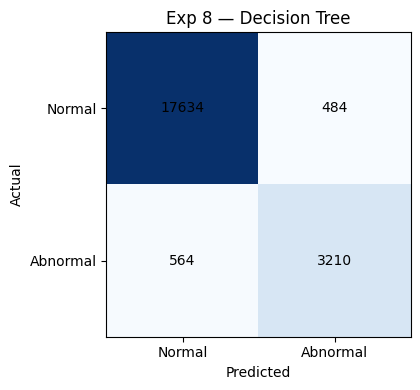


Training Random Forest...
Random Forest classification report:
              precision    recall  f1-score   support

      Normal       0.97      1.00      0.98     18118
    Abnormal       0.98      0.87      0.92      3774

    accuracy                           0.97     21892
   macro avg       0.98      0.93      0.95     21892
weighted avg       0.97      0.97      0.97     21892



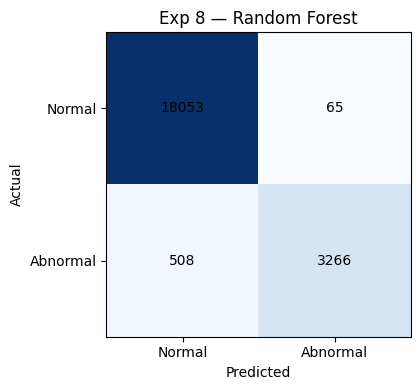


Training Logistic Regression...
Logistic Regression classification report:
              precision    recall  f1-score   support

      Normal       0.96      0.88      0.92     18118
    Abnormal       0.59      0.83      0.69      3774

    accuracy                           0.87     21892
   macro avg       0.78      0.85      0.80     21892
weighted avg       0.90      0.87      0.88     21892



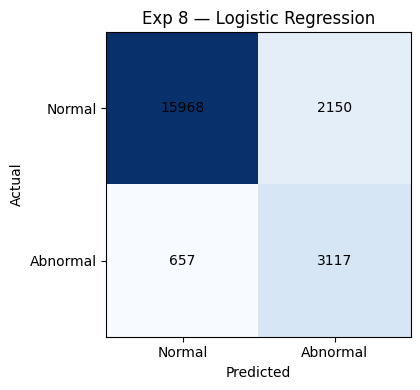


Training RBF SVM...
RBF SVM classification report:
              precision    recall  f1-score   support

      Normal       0.98      0.96      0.97     18118
    Abnormal       0.81      0.91      0.86      3774

    accuracy                           0.95     21892
   macro avg       0.90      0.93      0.91     21892
weighted avg       0.95      0.95      0.95     21892



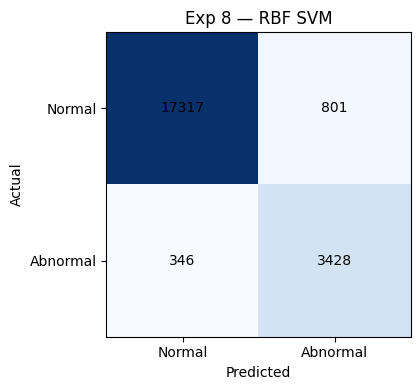


Training K-Nearest Neighbors...
K-Nearest Neighbors classification report:
              precision    recall  f1-score   support

      Normal       0.98      0.99      0.98     18118
    Abnormal       0.96      0.89      0.92      3774

    accuracy                           0.97     21892
   macro avg       0.97      0.94      0.95     21892
weighted avg       0.97      0.97      0.97     21892



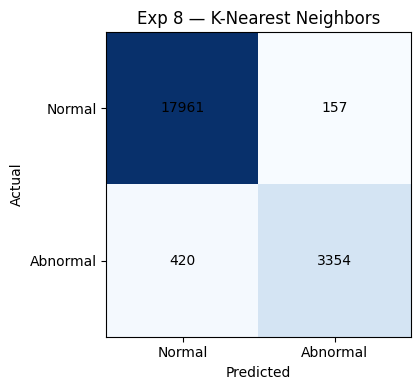

In [8]:
# 4. Train, predict, evaluate, and save confusion matrices
results = []
output_dir = Path("exp8_results")
output_dir.mkdir(exist_ok=True)

for name, model in models.items():
    print(f"\nTraining {name}...")
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (abnormal)": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall (abnormal)": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 (abnormal)": f1_score(
            y_test, predictions, zero_division=0
        ),
    })

    print(f"{name} classification report:")
    print(classification_report(
        y_test,
        predictions,
        labels=[0, 1],
        target_names=["Normal", "Abnormal"],
        zero_division=0,
    ))

    matrix = confusion_matrix(y_test, predictions, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(5, 4))
    ax.imshow(matrix, cmap="Blues")
    ax.set(
        title=f"Exp 8 — {name}",
        xlabel="Predicted",
        ylabel="Actual",
        xticks=[0, 1],
        yticks=[0, 1],
        xticklabels=["Normal", "Abnormal"],
        yticklabels=["Normal", "Abnormal"],
    )
    for (row, col), value in np.ndenumerate(matrix):
        ax.text(col, row, str(value), ha="center", va="center")
    fig.tight_layout()
    fig.savefig(
        output_dir / f"{name.lower().replace(' ', '_')}_confusion.png",
        dpi=150,
    )
    plt.show()
    plt.close(fig)

In [9]:
# 5. Compile and display final model performance comparison
results_df = pd.DataFrame(results).sort_values(
    "F1 (abnormal)", ascending=False
)
results_df.to_csv(output_dir / "model_comparison.csv", index=False)

print("\nModel Comparison:")
display(results_df)
print(f"\nSaved performance scores and plots in: {output_dir.resolve()}")


Model Comparison:


,Model,Accuracy,Precision (abnormal),Recall (abnormal),F1 (abnormal)
4,K-Nearest Neighbors,0.973643,0.955283,0.888712,0.920796
1,Random Forest,0.973826,0.980486,0.865395,0.919353
0,Decision Tree,0.952129,0.868977,0.850556,0.859668
3,RBF SVM,0.947606,0.810594,0.908320,0.856679
2,Logistic Regression,0.871780,0.591798,0.825914,0.689525



Saved performance scores and plots in: /content/exp8_results
